## Introduction

Natural Language Processing, or NLP, is the field of data science concerned with processing and analyzing unstructured data like human speech and text. One of the uses of NLP is in analyzing massive sets of qualitative text data, like customer reviews, in order to observe insights and trends in customer satisfaction. In the following notebook a logistic regression model is used for an NLP sentiment analysis task by identifying which words in a review most strongly predict a positive or negative score. The initial data was pulled from Kaggle's Disneyland Reviews dataset, which is composed of thousands of reviews from customers to various Disneyland locations across the globe. 

## Data Exploration

Import the necessary dependencies from pandas, numpy, and sci-kit learn.

In [146]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import confusion_matrix


Read the CSV and import the first 50,000 rows of data into a pandas dataframe. 

In [ ]:
df = pd.read_csv("data/DisneylandReviews.csv", 
                 nrows=50000, encoding='utf-8', encoding_errors='ignore')
df = df.set_index(df.columns[0])
df.head()

,Rating,Year_Month,Reviewer_Location,Review_Text,Branch
Review_ID,,,,,
670772142,4,2019-4,Australia,If you've ever been to Disneyland anywhere you...,Disneyland_HongKong
670682799,4,2019-5,Philippines,Its been a while since d last time we visit HK...,Disneyland_HongKong
670623270,4,2019-4,United Arab Emirates,Thanks God it wasn t too hot or too humid wh...,Disneyland_HongKong
670607911,4,2019-4,Australia,HK Disneyland is a great compact park. Unfortu...,Disneyland_HongKong
670607296,4,2019-4,United Kingdom,"the location is not in the city, took around 1...",Disneyland_HongKong


Examine the distribution of scores across the whole dataset.

Rating
5    23146
4    10775
3     5109
2     2127
1     1499
Name: count, dtype: int64
Average rating =  4.217695048762191


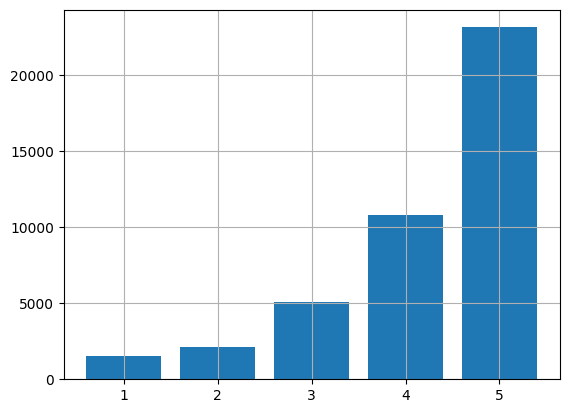

In [148]:
score_distribution = df['Rating'].value_counts()
fig, ax = plt.subplots(1,1)
ax.bar(score_distribution.index,score_distribution)
ax.grid()

print(score_distribution)
print('Average rating = ', df['Rating'].mean())

The average score is approximately 4.22 / 5 stars, and the distribution of scores is heavily skewed towards 5-star ratings. To avoid bias from class imbalance, an equal number of reviews will be sampled from each class, such that n = 1499 (The total count of the smallest class).

In [149]:
resampled_df = df.groupby('Rating').sample(1499,random_state=10)
resampled_df['Rating'].value_counts()

Rating
1    1499
2    1499
3    1499
4    1499
5    1499
Name: count, dtype: int64

## Data Preparation

Add a sentiment column which codes a 1 for reviews with a rating higher than 3/5, and a 0 for any other rating. This creates a binary variable to be used as target values for the logistic regression Then, the review text and newly created sentiment column are converted to lists to prepare for further data processing.

In [150]:
resampled_df['Sentiment'] = [1 if row > 3 else 0 for row in resampled_df['Rating']]

reviews = list(resampled_df['Review_Text'])
sentiment = list(resampled_df['Sentiment'])

The text from the reviews is converted into sparse vectors using tf-idf (term frequency-inverse document frequency), which creates n-dimensional row vectors where n is the number of unique words in the dataset, and each column in the vector represents a specific word. The value represents the frequency that that word appears in the review, weighted against how frequently it appears across every review. This helps isolate useful and unique words while giving less weight to overly common words like 'the' or 'and'. The list of sentiment values is converted to a 1-dimensional array to be used as y values for the logistic regression model. 

In [151]:
vectorizer = TfidfVectorizer(
    stop_words='english',
    ngram_range=(1,1),
    min_df=10
)

tf_vectors = vectorizer.fit_transform(reviews)
y_values = np.array(sentiment)

## Modeling

Dataset is split into an 80/20 train/test split to preserve unseen data for model testing and validation.

In [152]:
x_train, x_test, y_train, y_test = train_test_split(tf_vectors, y_values, test_size=0.20, random_state=10)

Logistic regression model is called and fit to the training data, accuracy and confusion matrix are calculated to measure goodness-of-fit.

In [153]:
model = LogisticRegression()

model.fit(x_train,y_train)
print('Intercept: ', model.intercept_)
print('Accuracy = ', model.score(x_test, y_test))

y_true = y_test
y_pred = model.predict(x_test)
confusion = confusion_matrix(y_true, y_pred)
print('Confusion Matrix: ')
print(confusion)

Intercept:  [-0.08960126]
Accuracy =  0.8545697131420947
Confusion Matrix: 
[[847  84]
 [134 434]]


Finally, features are extracted and converted from column values back to words, and are matched with their coefficients to get a value coefficient for each word. A dataframe is created to store the coefficients for all words in the corpus.

In [154]:
features = vectorizer.get_feature_names_out()
coefs = model.coef_.flatten()

sentiment_values = pd.DataFrame()
sentiment_values['word'] = features
sentiment_values['sentiment'] = coefs
sentiment_values.head()

,word,sentiment
0,00,-1.376367
1,000,-0.272662
2,00am,-0.016876
3,00pm,-0.128784
4,08,0.201502


After sorting all words by the their sentiment value from highest to lowest, we can plot the 10 highest sentiment value words and 10 lowest sentiment value words to identify terms that strongly predicted high or low ratings.

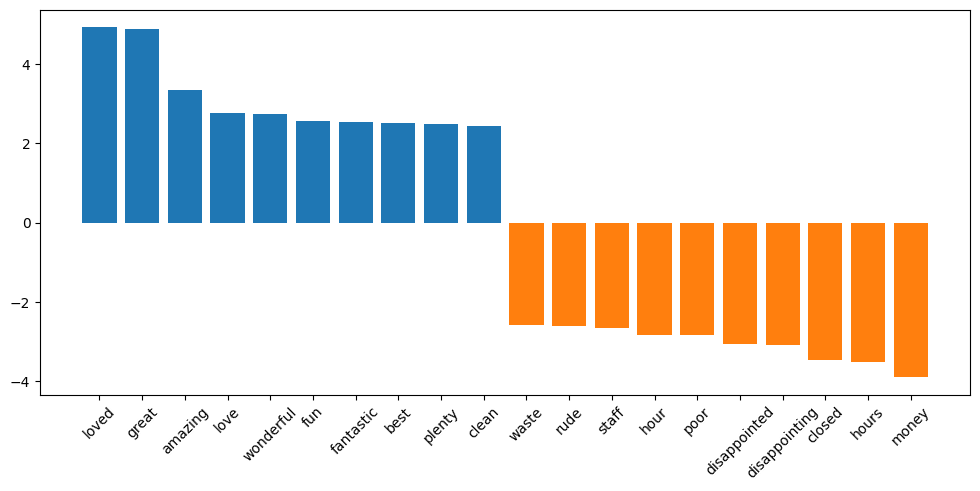

In [155]:
sorted_sentiments = sentiment_values.sort_values(by='sentiment', ascending=False)

fig,axs = plt.subplots(figsize=(12,5))
axs.bar(sorted_sentiments['word'][:10],sorted_sentiments['sentiment'][:10])
axs.bar(sorted_sentiments['word'][-10:],sorted_sentiments['sentiment'][-10:])
axs.tick_params(axis='x', labelrotation=45)
plt.show()

Observing the results, it seems that highly positive words tended to be general positive adjectives or emotions, like "amazing", "loved", or "great", with one term, "clean", appearing as a more specific keyword. Highly negative words, however, were slightly more specific, and some could be attributed to specific issues in the customer's experience, like "staff", "rude", "hours", or "money", implying long wait times, high costs, and unfriendly staff. Based on this trend, it would seem that when users have a positive experience, they are more likely to attribute it to a broad, overall experience, while customers who had a negative experience are highly aware of what exactly made their experience subpar. 